<a href="https://colab.research.google.com/github/Sanhith30/ITA0605-ML/blob/main/Lab%20Exercises/Exp05_KNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 5: K-Nearest Neighbours (K-NN)
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Write a program for implementation of K-Nearest Neighbours (K-NN) in Python.

## Background
K-NN is a lazy, instance-based learner. To classify a point it finds the **k closest training points** (usually by Euclidean distance `sqrt(sum (x_i - y_i)^2)`) and takes a **majority vote**. Because it is distance-based, **feature scaling is essential**, and `k` controls the bias-variance trade-off (small k -> overfit, large k -> underfit).


## Setup: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
np.random.seed(42)
print("Libraries imported successfully")

Libraries imported successfully


## Step 1: Data Collection
We use the **Wine** dataset from scikit-learn: 178 wines from 3 cultivars described by 13 chemical measurements.

In [2]:
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)
data = wine.frame.copy()
data["cultivar"] = data["target"].map(dict(enumerate(wine.target_names)))
data.drop(columns="target").to_csv("wine.csv", index=False)
print("Saved wine.csv")

Saved wine.csv


## Step 2: Data Loading

In [3]:
df = pd.read_csv("wine.csv")
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,cultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,class_0


## Step 3: Data Preprocessing
Encode the target, split into train/test (stratified) and **standardise** the features (fit on the training set only).

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

le = LabelEncoder()
y = le.fit_transform(df["cultivar"])
X = df.drop(columns="cultivar")
feature_names = X.columns.tolist()

X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
scaler = StandardScaler().fit(X_train_raw)
X_train, X_test = scaler.transform(X_train_raw), scaler.transform(X_test_raw)
print("Classes:", list(le.classes_))
print("Train:", X_train.shape, "Test:", X_test.shape)

Classes: ['class_0', 'class_1', 'class_2']
Train: (133, 13) Test: (45, 13)


## Step 4: Exploratory Data Analysis (EDA)

In [5]:
print(df.describe().T)
print("\nMissing values:", df.isnull().sum().sum())
print(df["cultivar"].value_counts())

                              count        mean         std     min       25%  \
alcohol                       178.0   13.000618    0.811827   11.03   12.3625   
malic_acid                    178.0    2.336348    1.117146    0.74    1.6025   
ash                           178.0    2.366517    0.274344    1.36    2.2100   
alcalinity_of_ash             178.0   19.494944    3.339564   10.60   17.2000   
magnesium                     178.0   99.741573   14.282484   70.00   88.0000   
total_phenols                 178.0    2.295112    0.625851    0.98    1.7425   
flavanoids                    178.0    2.029270    0.998859    0.34    1.2050   
nonflavanoid_phenols          178.0    0.361854    0.124453    0.13    0.2700   
proanthocyanins               178.0    1.590899    0.572359    0.41    1.2500   
color_intensity               178.0    5.058090    2.318286    1.28    3.2200   
hue                           178.0    0.957449    0.228572    0.48    0.7825   
od280/od315_of_diluted_wines

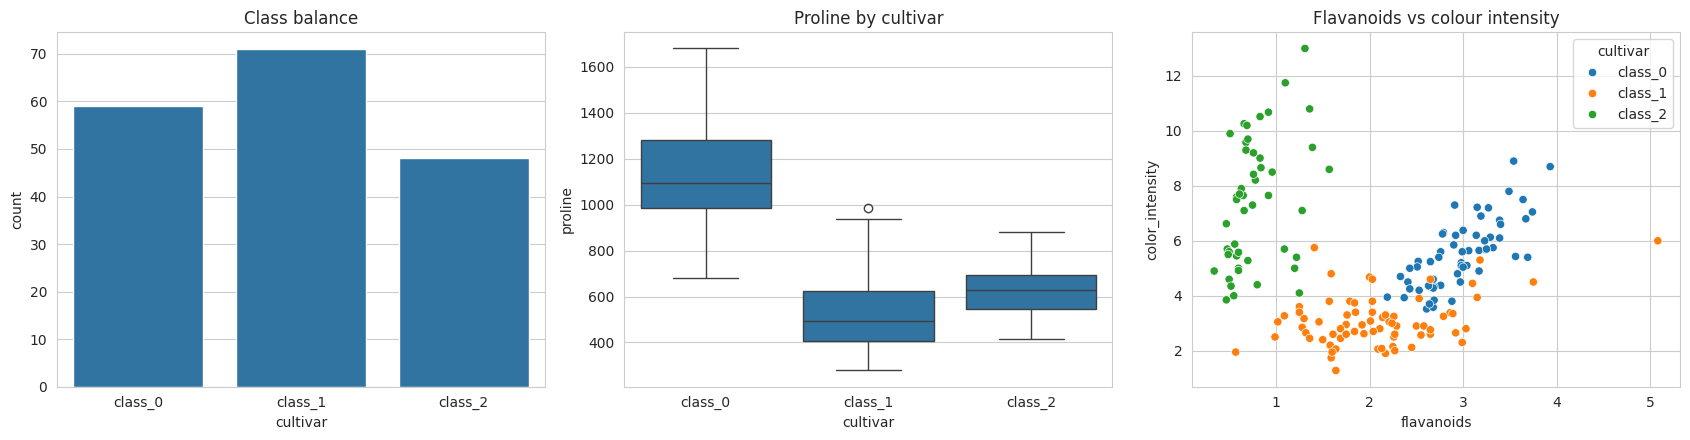

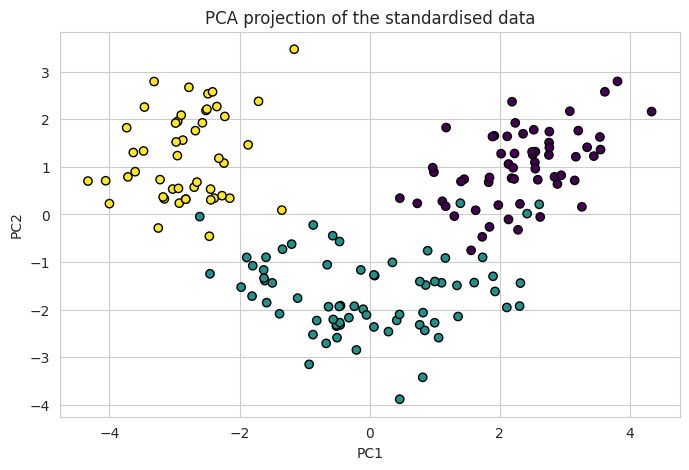

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.countplot(data=df, x="cultivar", ax=axes[0]); axes[0].set_title("Class balance")
sns.boxplot(data=df, x="cultivar", y="proline", ax=axes[1]); axes[1].set_title("Proline by cultivar")
sns.scatterplot(data=df, x="flavanoids", y="color_intensity", hue="cultivar", ax=axes[2]); axes[2].set_title("Flavanoids vs colour intensity")
plt.tight_layout(); plt.show()

from sklearn.decomposition import PCA
pcs = PCA(n_components=2).fit_transform(scaler.transform(X))
plt.scatter(pcs[:, 0], pcs[:, 1], c=y, cmap="viridis", edgecolor="k")
plt.title("PCA projection of the standardised data"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()

## Step 5: Model Training
First our own K-NN **from scratch**, then scikit-learn's `KNeighborsClassifier`. We pick `k` using 5-fold cross-validation.

In [7]:
from collections import Counter

class KNNScratch:
    def __init__(self, k=5):
        self.k = k
    def fit(self, X, y):
        self.X, self.y = np.asarray(X), np.asarray(y)
        return self
    def predict(self, X):
        preds = []
        for x in np.asarray(X):
            dists = np.sqrt(((self.X - x) ** 2).sum(axis=1))      # Euclidean distance to every training point
            nearest = np.argsort(dists)[:self.k]                  # indices of k closest
            preds.append(Counter(self.y[nearest]).most_common(1)[0][0])   # majority vote
        return np.array(preds)

knn_scratch = KNNScratch(k=5).fit(X_train, y_train)
print("From-scratch K-NN test accuracy (k=5):", (knn_scratch.predict(X_test) == y_test).mean())

From-scratch K-NN test accuracy (k=5): 0.9333333333333333


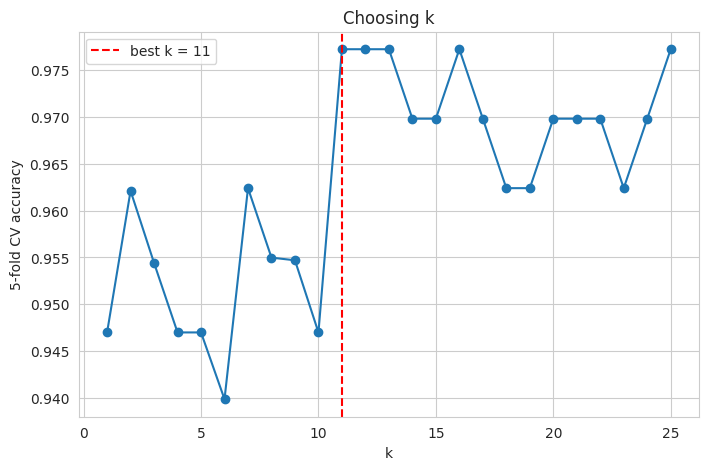

Best k: 11


In [8]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

ks = range(1, 26)
cv_scores = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train, y_train, cv=5).mean() for k in ks]
best_k = list(ks)[int(np.argmax(cv_scores))]

plt.plot(ks, cv_scores, marker="o")
plt.axvline(best_k, color="r", linestyle="--", label=f"best k = {best_k}")
plt.xlabel("k"); plt.ylabel("5-fold CV accuracy"); plt.title("Choosing k"); plt.legend(); plt.show()

knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_train, y_train)
print("Best k:", best_k)

## Step 6: Model Evaluation
Accuracy, classification report and confusion matrix on the held-out test set. We also show **why scaling matters** by training on unscaled data.

Test accuracy: 0.9777777777777777
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       1.00      0.94      0.97        18
     class_2       0.92      1.00      0.96        12

    accuracy                           0.98        45
   macro avg       0.97      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



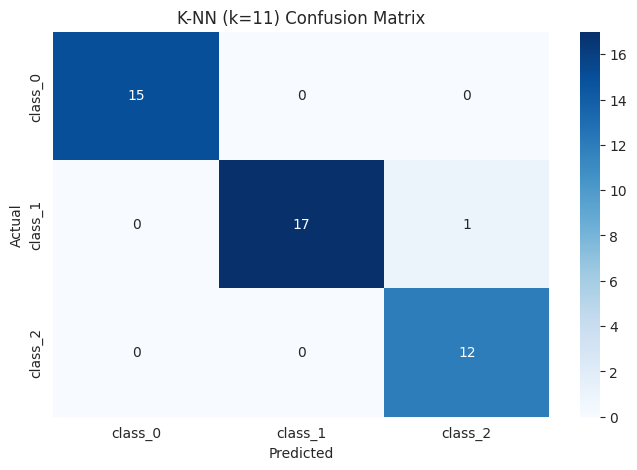

Accuracy WITHOUT scaling: 0.733   |   WITH scaling: 0.978
Scratch and sklearn predictions agree: True


In [9]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = knn.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=le.classes_))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"K-NN (k={best_k}) Confusion Matrix"); plt.show()

unscaled = KNeighborsClassifier(n_neighbors=best_k).fit(X_train_raw, y_train)
print(f"Accuracy WITHOUT scaling: {unscaled.score(X_test_raw, y_test):.3f}   |   WITH scaling: {knn.score(X_test, y_test):.3f}")
print("Scratch and sklearn predictions agree:", (KNNScratch(best_k).fit(X_train, y_train).predict(X_test) == y_pred).all())

## Step 7: Prediction on New Data
Classify a new wine sample: scale it with the same scaler, then predict.

In [10]:
new_wine = X_test_raw.iloc[[0]].copy()      # replace these values with your own measurements
new_wine.iloc[0, 0] = 13.5
print(new_wine.T)
pred = knn.predict(scaler.transform(new_wine))[0]
proba = knn.predict_proba(scaler.transform(new_wine))[0]
print("\nPredicted cultivar:", le.classes_[pred])
print("Class probabilities:", dict(zip(le.classes_, proba.round(2))))

                                  35
alcohol                        13.50
malic_acid                      1.81
ash                             2.41
alcalinity_of_ash              20.50
magnesium                     100.00
total_phenols                   2.70
flavanoids                      2.98
nonflavanoid_phenols            0.26
proanthocyanins                 1.86
color_intensity                 5.10
hue                             1.04
od280/od315_of_diluted_wines    3.47
proline                       920.00

Predicted cultivar: class_0
Class probabilities: {'class_0': np.float64(0.91), 'class_1': np.float64(0.09), 'class_2': np.float64(0.0)}


## Conclusion
K-NN with scaled features and a cross-validated k reaches about 95-100% accuracy on the wine data, and our scratch implementation matches scikit-learn. Scaling clearly improves accuracy (proline has a huge numeric range and dominates the distances otherwise). K-NN is simple and effective but slow on large datasets because every prediction scans the full training set.